<a href="https://colab.research.google.com/github/deva7102bratta/AI_dog_image_generation/blob/main/notebooks/notebook/dogImageGen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()

In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

devabrattayumnam_dogimage_30k_path = kagglehub.dataset_download('devabrattayumnam/dogimage-30k')
devabrattayumnam_models_keras_default_1_path = kagglehub.model_download('devabrattayumnam/models/Keras/default/1')

print('Data source import complete.')


In [ ]:
from PIL import Image
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import shutil
import matplotlib.pyplot as plt

In [ ]:
DOGS = "/kaggle/input/datasets/devabrattayumnam/dogimage-30k/DogImage"

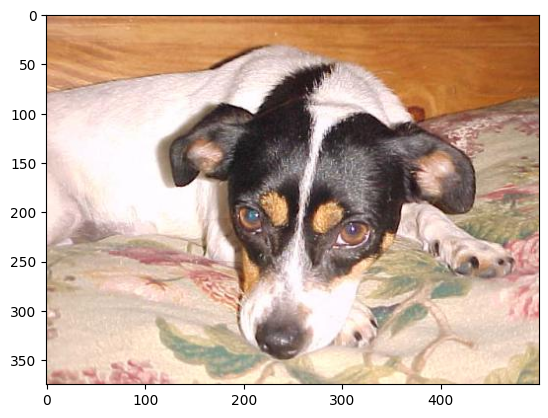

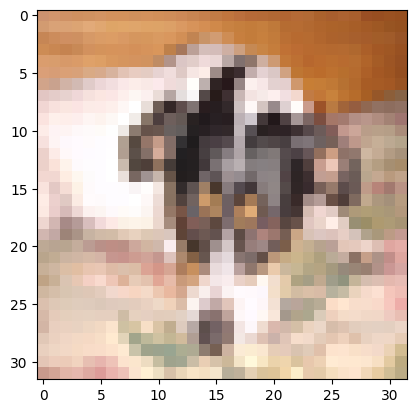

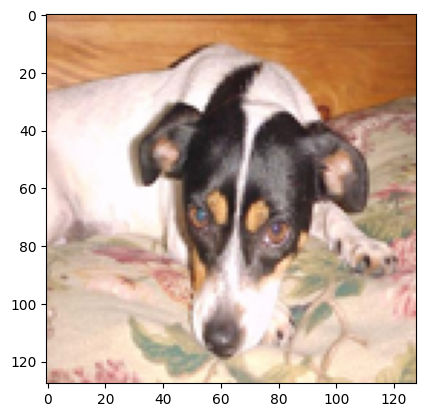

In [ ]:
file = os.listdir(DOGS)[1]
path = os.path.join(DOGS, file)

img = Image.open(path)
plt.imshow(img)

img_2 = Image.open(path).resize((32, 32))
plt.figure()
plt.imshow(img_2)

img_3 = Image.open(path).resize((128, 128))
plt.figure()
plt.imshow(img_3)

In [ ]:
IMG_SIZE = 128

images = []

for file in os.listdir(DOGS):
    if file.lower().endswith((".jpg", ".jpeg", ".png")):
        path = os.path.join(DOGS, file)
        try:
            img = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
            arr = np.array(img, dtype=np.float32)
            images.append(arr/127.5 - 1.0)
        except Exception as e:
            print("Skipped:", file, e)
images = np.array(images)
print("Dataset shape:", images.shape)

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Skipped: 11702.jpg cannot identify image file '/kaggle/input/datasets/devabrattayumnam/dogimage-30k/DogImage/11702.jpg'
Dataset shape: (29997, 128, 128, 3)


In [ ]:
images = images/127.5 - 1.0

In [ ]:
print("Shape:", images.shape)
print("Min:", images.min())
print("Max:", images.max())
print("Data type:", images.dtype)

Shape: (29997, 128, 128, 3)
Min: -1.0078431
Max: -0.99215686
Data type: float32


In [ ]:
BATCH_SIZE = 64
dataset = tf.data.Dataset.from_tensor_slices(images)
dataset = dataset.shuffle(len(images))
dataset = dataset.batch(BATCH_SIZE)
dataset = dataset.prefetch(tf.data.AUTOTUNE)


I0000 00:00:1791286489.363157      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791286489.367173      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [ ]:
# # ============================================================
# # CLEAN DOG DATASET
# # ============================================================

# import os
# import shutil
# from PIL import Image

# # ============================================================
# # PATHS
# # ============================================================

# SOURCE = "/kaggle/input/datasets/devabrattayumnam/dogimages-50k/DogImage"

# DESTINATION = "/kaggle/working/DogImage_clean"

# os.makedirs(
#     DESTINATION,
#     exist_ok=True
# )

# # ============================================================
# # CLEAN DATASET
# # ============================================================

# valid_count = 0
# bad_count = 0
# bad_files = []

# print("Checking images...\n")

# for file in os.listdir(SOURCE):

#     # Only image files
#     if not file.lower().endswith(
#         (".jpg", ".jpeg", ".png")
#     ):
#         continue

#     source_path = os.path.join(
#         SOURCE,
#         file
#     )

#     destination_path = os.path.join(
#         DESTINATION,
#         file
#     )

#     try:

#         # ----------------------------------------------------
#         # Check empty file
#         # ----------------------------------------------------

#         if os.path.getsize(source_path) == 0:

#             raise ValueError(
#                 "Empty file"
#             )

#         # ----------------------------------------------------
#         # Fully load image
#         # ----------------------------------------------------

#         with Image.open(source_path) as img:

#             img.load()

#             # Make sure it can become RGB
#             img.convert("RGB")

#         # ----------------------------------------------------
#         # Valid → copy
#         # ----------------------------------------------------

#         shutil.copy2(
#             source_path,
#             destination_path
#         )

#         valid_count += 1

#     except Exception as e:

#         bad_count += 1

#         bad_files.append(
#             (file, str(e))
#         )


# # ============================================================
# # RESULTS
# # ============================================================

# print("\n========================================")
# print("CLEANING COMPLETE")
# print("========================================")

# print(
#     "Valid images:",
#     valid_count
# )

# print(
#     "Bad images:",
#     bad_count
# )

# print(
#     "Clean dataset:",
#     DESTINATION
# )

# if bad_files:

#     print("\nFiles excluded:")

#     for file, error in bad_files:

#         print(
#             file,
#             "->",
#             error
#         )

In [ ]:
# # ==============================
# # DATASET CONFIGURATION
# # ==============================

# IMG_SIZE = 128
# BATCH_SIZE = 64


# # ==============================
# # COLLECT + VALIDATE IMAGE PATHS
# # ==============================

# from PIL import Image

# image_paths = []
# bad_files = []

# for file in os.listdir(DOGS):

#     if file.lower().endswith(
#         (".jpg", ".jpeg", ".png")
#     ):

#         path = os.path.join(
#             DOGS,
#             file
#         )

#         try:

#             # Check if file is empty
#             if os.path.getsize(path) == 0:
#                 raise ValueError("Empty file")

#             # Check if image is actually valid
#             with Image.open(path) as img:
#                 img.verify()

#             # Image is valid
#             image_paths.append(path)

#         except Exception as e:

#             bad_files.append(
#                 (file, str(e))
#             )


# print(
#     "Valid images:",
#     len(image_paths)
# )

# print(
#     "Bad images:",
#     len(bad_files)
# )


# # Show bad files
# if bad_files:

#     print("\nBad files found:")

#     for file, error in bad_files[:20]:

#         print(
#             file,
#             "->",
#             error
#         )


# # ==============================
# # LOAD + PREPROCESS IMAGE
# # ==============================

# def load_image(path):

#     # Read image file
#     img = tf.io.read_file(path)

#     # Decode into RGB
#     img = tf.io.decode_image(
#         img,
#         channels=3,
#         expand_animations=False
#     )

#     # Resize
#     img = tf.image.resize(
#         img,
#         (IMG_SIZE, IMG_SIZE)
#     )

#     # Convert to float32
#     img = tf.cast(
#         img,
#         tf.float32
#     )

#     # Normalize [0,255] -> [-1,1]
#     img = img / 127.5 - 1.0

#     # Explicit shape
#     img.set_shape(
#         (IMG_SIZE, IMG_SIZE, 3)
#     )

#     return img


# # ==============================
# # CREATE DATASET
# # ==============================

# dataset = tf.data.Dataset.from_tensor_slices(
#     image_paths
# )


# # ==============================
# # SHUFFLE
# # ==============================

# dataset = dataset.shuffle(
#     buffer_size=min(len(image_paths), 5000),
#     reshuffle_each_iteration=True
# )


# # ==============================
# # LOAD IMAGES IN PARALLEL
# # ==============================

# dataset = dataset.map(
#     load_image,
#     num_parallel_calls=tf.data.AUTOTUNE
# )


# # ==============================
# # BATCH
# # ==============================

# dataset = dataset.batch(
#     BATCH_SIZE,
#     drop_remainder=True
# )


# # ==============================
# # PREFETCH
# # ==============================

# dataset = dataset.prefetch(
#     tf.data.AUTOTUNE
# )


# # ==============================
# # DATASET INFORMATION
# # ==============================

# steps_per_epoch = len(image_paths) // BATCH_SIZE

# print(
#     "\nSteps per epoch:",
#     steps_per_epoch
# )

# print(
#     "Images processed per epoch:",
#     steps_per_epoch * BATCH_SIZE
# )


# # ==============================
# # VERIFY DATASET
# # ==============================

# for real_images in dataset.take(1):

#     print(
#         "\nBatch shape:",
#         real_images.shape
#     )

#     print(
#         "Data type:",
#         real_images.dtype
#     )

#     print(
#         "Minimum:",
#         tf.reduce_min(real_images).numpy()
#     )

#     print(
#         "Maximum:",
#         tf.reduce_max(real_images).numpy()
#     )

In [ ]:
# generator = keras.Sequential([
#     # Input: 100 random numbers
#     layers.Input(shape=(100,)),

#     # 100 → 16×16×512
#     layers.Dense(16 * 16 * 512),
#     layers.ReLU(),
#     layers.Reshape((16, 16, 512)),

#     # 16×16×512 → 32×32×256
#     layers.Conv2DTranspose(256, kernel_size=4, strides=2, padding="same"),
#     layers.BatchNormalization(),
#     layers.ReLU(),

#     # Refinement
#     layers.Conv2D(256, kernel_size=3, padding="same"),
#     layers.BatchNormalization(),
#     layers.ReLU(),

#     # 32×32×256 → 64×64×128
#     layers.Conv2DTranspose(128, kernel_size=4, strides=2, padding="same"),
#     layers.BatchNormalization(),
#     layers.ReLU(),

#     # Refinement
#     layers.Conv2D(128, kernel_size=3, padding="same"),
#     layers.BatchNormalization(),
#     layers.ReLU(),

#     # 64×64×128 → 128×128×64
#     layers.Conv2DTranspose(64, kernel_size=4, strides=2, padding="same"),
#     layers.BatchNormalization(),
#     layers.ReLU(),

#     # Refinement
#     layers.Conv2D(64, kernel_size=3, padding="same"),
#     layers.BatchNormalization(),
#     layers.ReLU(),

#     # Final image: 128×128×64 → 128×128×3
#     layers.Conv2D(3, kernel_size=3, padding="same"),
#     layers.Activation("tanh")
# ])

In [ ]:
# discriminator = keras.Sequential([
#     # Input: 128×128×3 RGB image
#     layers.Input(shape=(128, 128, 3)),

#     # 128×128×3 → 64×64×64
#     layers.Conv2D(64, kernel_size=4, strides=2, padding="same"),
#     layers.LeakyReLU(0.2),

#     # Refinement
#     layers.Conv2D(64, kernel_size=3, padding="same"),
#     layers.LeakyReLU(0.2),

#     # 64×64×64 → 32×32×128
#     layers.Conv2D(128, kernel_size=4, strides=2, padding="same"),
#     layers.BatchNormalization(),
#     layers.LeakyReLU(0.2),

#     # Refinement
#     layers.Conv2D(128, kernel_size=3, padding="same"),
#     layers.BatchNormalization(),
#     layers.LeakyReLU(0.2),

#     # 32×32×128 → 16×16×256
#     layers.Conv2D(256, kernel_size=4, strides=2, padding="same"),
#     layers.BatchNormalization(),
#     layers.LeakyReLU(0.2),

#     # Refinement
#     layers.Conv2D(256, kernel_size=3, padding="same"),
#     layers.BatchNormalization(),
#     layers.LeakyReLU(0.2),

#     # 16×16×256 → 8×8×512
#     layers.Conv2D(512, kernel_size=4, strides=2, padding="same"),
#     layers.BatchNormalization(),
#     layers.LeakyReLU(0.2),

#     # Convert feature maps to one value
#     layers.Flatten(),

#     # Real/Fake score
#     layers.Dense(1)
# ])

In [ ]:
MODEL_PATH = "/kaggle/input/models/devabrattayumnam/models/keras/default/1"
os.listdir(MODEL_PATH)

['discriminator_epoch_230.keras', 'generator_epoch_230.keras']

In [ ]:
discriminator = tf.keras.models.load_model(f"{MODEL_PATH}/discriminator_epoch_260.keras")

generator = tf.keras.models.load_model(f"{MODEL_PATH}/generator_epoch_260.keras")

In [ ]:
# Binary Cross-Entropy loss
cross_entropy = keras.losses.BinaryCrossentropy(
    from_logits=True
)


# ------------------------
# Discriminator Loss
# -------------------------
def discriminator_loss(real_output, fake_output):

    # Real images should be classified as 1
    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    # Generated images should be classified as 0
    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    # Total Discriminator loss
    total_loss = real_loss + fake_loss

    return total_loss


# -------------------------
# Generator Loss
# -------------------------
def generator_loss(fake_output):

    # Generator wants fake images to be classified as real (1)
    loss = cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

    return loss

In [ ]:
# Generator optimizer
generator_optimizer = keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

# Discriminator optimizer
discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

In [ ]:
@tf.function
def train_step(real_images):

    # Number of images in this batch
    batch_size = tf.shape(real_images)[0]

    # Generate random noise
    noise = tf.random.normal([batch_size, 100])

    # Record operations for gradient calculation
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        # Generator creates fake dogs
        fake_images = generator(noise, training=True)

        # Discriminator examines real and fake images
        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        # Calculate losses
        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(
            real_output,
            fake_output
        )

    # Calculate gradients
    gen_gradients = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    disc_gradients = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    # Update weights
    generator_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss

In [ ]:
# =========================
# TRAINING SETTINGS
# =========================

BATCH_SIZE = 64

steps_per_epoch = 465

print("Steps per epoch:", steps_per_epoch)

# =========================
# FIXED NOISE
# =========================

NUM_EXAMPLES = 16

seed = tf.random.normal(
    [NUM_EXAMPLES, 100]
)

# =========================
# GENERATE SAMPLE IMAGES
# =========================

os.makedirs("/kaggle/working/dogen", exist_ok=True)

def generate_and_save_images(
    model,
    epoch,
    test_input
):

    predictions = model(
        test_input,
        training=False
    )

    plt.figure(figsize=(8, 8))

    for i in range(predictions.shape[0]):

        plt.subplot(4, 4, i + 1)

        # Convert -1..1 back to 0..1
        image = (predictions[i] + 1) / 2

        plt.imshow(image)
        plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        f"/kaggle/working/dogen/dog_epoch_{epoch:03d}.png"
    )
    plt.close()


Steps per epoch: 465


In [ ]:
# Generate 16 random dogs
noise = tf.random.normal([16, 100])

generated_images = generator(
    noise,
    training=False
)

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    image = (generated_images[i] + 1) / 2

    plt.imshow(image)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
for epoch in range(261, 1001):

    print(f"\n========== Epoch {epoch}/1000 ==========")

    for batch_no, real_images in enumerate(
        dataset,
        start=1
    ):

        gen_loss, disc_loss = train_step(
            real_images
        )

        if batch_no == 1 or batch_no % 50 == 0:
            print(
                f"Batch {batch_no}/{steps_per_epoch} | "
                f"Generator Loss: {gen_loss.numpy():.4f} | "
                f"Discriminator Loss: {disc_loss.numpy():.4f}"
            )

    generate_and_save_images(
        generator,
        epoch,
        seed
    )

    print(f"Epoch {epoch} completed.")

    if epoch % 10 == 0:
        generator.save(
            f"/kaggle/working/generator_epoch_{epoch}.keras"
        ) all
        discriminator.save(
            f"/kaggle/working/discriminator_epoch_{epoch}.keras"
        )

        print(f"Checkpoint saved at epoch {epoch}")

print("\n========== TRAINING COMPLETE: EPOCH 1000 ==========")


========== Epoch 261/1000 ==========
Batch 1/465 | Generator Loss: 0.6557 | Discriminator Loss: 1.1849
Batch 50/465 | Generator Loss: 2.1071 | Discriminator Loss: 1.7813
Batch 100/465 | Generator Loss: 0.6334 | Discriminator Loss: 1.1999
Batch 150/465 | Generator Loss: 0.4918 | Discriminator Loss: 1.3841
Batch 200/465 | Generator Loss: 0.9822 | Discriminator Loss: 1.0334
Batch 250/465 | Generator Loss: 0.7696 | Discriminator Loss: 1.1146
Batch 300/465 | Generator Loss: 1.1131 | Discriminator Loss: 0.9646
Batch 350/465 | Generator Loss: 2.2594 | Discriminator Loss: 1.4091
Batch 400/465 | Generator Loss: 0.5199 | Discriminator Loss: 1.2887
Batch 450/465 | Generator Loss: 0.9893 | Discriminator Loss: 0.9886
Epoch 261 completed.

========== Epoch 262/1000 ==========
Batch 1/465 | Generator Loss: 1.3427 | Discriminator Loss: 0.8803
Batch 50/465 | Generator Loss: 1.6539 | Discriminator Loss: 1.1591
Batch 100/465 | Generator Loss: 0.3983 | Discriminator Loss: 1.5618
Batch 150/465 | Generator

In [ ]:
# Save Generator
generator.save(
    "/kaggle/working/generator_final_v2.keras"
)

discriminator.save("/kaggle/working/discriminator_final_v2.keras")

print("Models saved successfully")

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras

discriminator = tf.keras.models.load_model(f"{MODEL_PATH}/discriminator_epoch_210.keras")

generator = tf.keras.models.load_model(f"{MODEL_PATH}/generator_epoch_210.keras")

# Save ALL discriminator state
old_trainable = [
    v.numpy().copy()
    for v in discriminator.trainable_variables
]

old_non_trainable = [
    v.numpy().copy()
    for v in discriminator.non_trainable_variables
]

# One real batch
real_images = next(iter(dataset))

batch_size = tf.shape(real_images)[0]
noise = tf.random.normal([batch_size, 100])

# Forward pass
fake_images = generator(noise, training=True)

real_output = discriminator(
    real_images,
    training=True
)

fake_output = discriminator(
    fake_images,
    training=True
)

# Loss
cross_entropy = keras.losses.BinaryCrossentropy(
    from_logits=True
)

disc_loss = (
    cross_entropy(
        tf.ones_like(real_output),
        real_output
    )
    +
    cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )
)

# Gradient
with tf.GradientTape() as tape:

    real_output = discriminator(
        real_images,
        training=True
    )

    fake_output = discriminator(
        fake_images,
        training=True
    )

    loss = (
        cross_entropy(
            tf.ones_like(real_output),
            real_output
        )
        +
        cross_entropy(
            tf.zeros_like(fake_output),
            fake_output
        )
    )

gradients = tape.gradient(
    loss,
    discriminator.trainable_variables
)

optimizer = keras.optimizers.Adam(
    learning_rate=0.00005,
    beta_1=0.5
)

# Apply ONE update
optimizer.apply_gradients(
    zip(
        gradients,
        discriminator.trainable_variables
    )
)

# Compare trainable state
trainable_change = sum(
    np.sum(
        np.abs(
            new.numpy() - old
        )
    )
    for new, old
    in zip(
        discriminator.trainable_variables,
        old_trainable
    )
)

# Compare non-trainable state
non_trainable_change = sum(
    np.sum(
        np.abs(
            new.numpy() - old
        )
    )
    for new, old
    in zip(
        discriminator.non_trainable_variables,
        old_non_trainable
    )
)

print("Trainable state change:")
print(trainable_change)

print("\nNon-trainable state change:")
print(non_trainable_change)